In [1]:
import sys
import os
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import display

from benchannot.prokaryotic.functional_analysis import categorize_functional_shifts, is_informative
from benchannot.paths import project_paths, validate_required_inputs

In [2]:
ORGANISMS = {
    "bacillus_subtilis": "B. subtilis",
    "escherichia_coli": "E. coli"
}

TOOLS_TO_EVALUATE = ['Prokka', 'Bakta', 'PGAP', 'eggNOG']

COLOR_MAP = {
    'Both Informative': '#66c2a5', 
    'Both Hypothetical': '#fc8d62', 
    'Over-Annotation': '#8da0cb',  
    'Under-Annotation': '#e78ac3'    
}

DATASET = "reproduced"  # "origin" or "reproduced"
PATHS = project_paths(DATASET)

OUTPUT_DIR = PATHS.analysis_output / "prokaryotic"
FIGURE_DIR = PATHS.figures / "prokaryotic"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print(f"Dataset: {DATASET}")
print(f"Analysis inputs: {OUTPUT_DIR}")

Dataset: reproduced
Analysis inputs: /home/bruno/BenchAnnot/analysis_benchannot/2_run/output/reproduced/prokaryotic


In [3]:
functional_analysis_inputs = {
    f"{organism} concordant CDS ({DATASET})": (
        OUTPUT_DIR / f"{organism}_concordant_CDS.csv"
    )
    for organism in ORGANISMS
}

validate_required_inputs(
    functional_analysis_inputs,
    context=f"prokaryotic functional analysis ({DATASET})",
)

In [4]:
print("Ground Truth Base Rates")
print("=======================\n")

for org_id, org_name in ORGANISMS.items():
    input_csv = OUTPUT_DIR/f"{org_id}_concordant_CDS.csv"
    if not os.path.exists(input_csv):
        print(f"Skipping {org_name} - {input_csv} not found.")
        continue

    df_func = pd.read_csv(input_csv)
    total = len(df_func)
    informative = df_func["product_Reference"].apply(is_informative).sum()
    non_informative = total - informative

    print(f"{org_name} (n = {total} CDS):")
    print(f"  Informative:       {informative:>4} ({informative/total*100:.1f}%)")
    print(f"  Non-informative:   {non_informative:>4} ({non_informative/total*100:.1f}%)")
    print()

Ground Truth Base Rates

B. subtilis (n = 3718 CDS):
  Informative:       2219 (59.7%)
  Non-informative:   1499 (40.3%)

E. coli (n = 3794 CDS):
  Informative:       2959 (78.0%)
  Non-informative:    835 (22.0%)



Saved /home/bruno/BenchAnnot/figures/prokaryotic/functional_annotation_merged.png


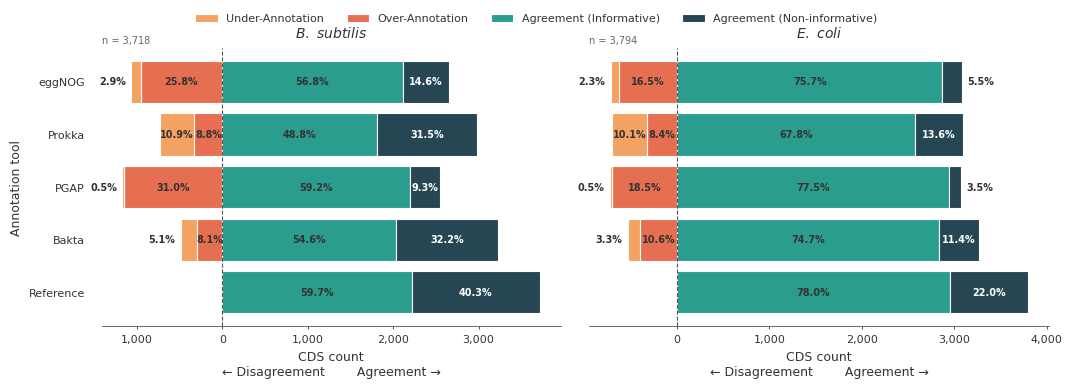

,Organism,Source,Category,Count
0,bacillus_subtilis,Reference,Both Informative,2219
1,bacillus_subtilis,Bakta,Both Informative,2030
2,bacillus_subtilis,PGAP,Both Informative,2201
3,bacillus_subtilis,Prokka,Both Informative,1813
4,bacillus_subtilis,eggNOG,Both Informative,2110
5,bacillus_subtilis,Reference,Both Hypothetical,1499
6,bacillus_subtilis,Bakta,Both Hypothetical,1199
7,bacillus_subtilis,PGAP,Both Hypothetical,346
8,bacillus_subtilis,Prokka,Both Hypothetical,1171
9,bacillus_subtilis,eggNOG,Both Hypothetical,541


In [5]:
from benchannot.plotting import (
    PLOT_NAMES,
    apply_style,
    plot_functional_shift_panels,
)
from benchannot.prokaryotic.functional_analysis import build_functional_plot_input

apply_style()

functional_panels = {}
functional_rows = []
for org_id, org_name in ORGANISMS.items():
    df_func = pd.read_csv(OUTPUT_DIR / f"{org_id}_concordant_CDS.csv")
    plot_input = build_functional_plot_input(df_func, TOOLS_TO_EVALUATE)
    functional_panels[PLOT_NAMES[org_id]] = plot_input
    tidy = (
        plot_input.rename_axis("Source")
        .reset_index()
        .melt(id_vars="Source", var_name="Category", value_name="Count")
    )
    tidy.insert(0, "Organism", org_id)
    functional_rows.append(tidy)

plot_functional_shift_panels(
    functional_panels,
    count_label="CDS",
    save_path=FIGURE_DIR / "functional_annotation_merged.png",
)

plot_data = pd.concat(functional_rows, ignore_index=True)
plot_data.to_csv(OUTPUT_DIR / "functional_annotation_plot_data.tsv", sep="\t", index=False)
display(plot_data.head(12))